# Session 7 — Convolutional Neural Networks

**Question:** the network now sees the pixels. Does that beat the handcrafted numbers?

**The plan**
1. Convolution, ReLU and pooling: first with small numbers we can check by hand.
2. A small CNN from scratch, tracing the shape after every layer.
3. A pretrained ResNet-18: frozen, then fine-tuned.
4. The scoreboard: every model of the course on the same lesions, with the same metric.

*Adapted to the milk10k-eda repo: the data location, the lesion-level split, the labels and the class weights come from our own `shared/` package and `outputs/` (Milestone 1), so every model is scored on the same lesions.*

### 0. Setup

We import the libraries and find the data.

#### 0.1 Libraries, data location and device

`torch` is new today. `device` says where the computations run: on a GPU if there is one, otherwise on the CPU. The code works on both; only the speed changes.

**Where the data comes from.** Locally, the images are read from `milk10k/images/` at the repo root, or from `MILK10K_DIR` / `MILK10K_IMAGES_DIR` if set (see README). On Colab (Runtime → GPU), the cell clones the repo and downloads MILK10k from the ISIC Archive once (345 MB).

In [1]:
# PURPOSE: load the libraries, find our repo and its data, and choose CPU or GPU.
# HOW: on Colab, clone the repo and download the images once; locally, walk up to the folder with shared/config.py.

import os
import sys
import time
import json
import copy
import zipfile
import subprocess
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# New libraries
import torch
import torch.nn as nn
import torch.nn.functional as F

from PIL import Image

REPO_URL = "https://github.com/bporto-eada/milk10k-eda.git"
MILK10K_URL = "https://isic-archive.s3.amazonaws.com/dois/10.34970-648456/milk10k.zip"   # DOI 10.34970/648456

if "google.colab" in sys.modules:                       # Colab: clone the repo and download the images once
    ROOT = Path("/content/milk10k-eda")
    if not (ROOT / "shared" / "config.py").is_file():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(ROOT)], check=True)
    image_dir = Path("/content/milk10k_images")
    if len(list(image_dir.glob("*.jpg"))) < 10_480:     # not extracted yet (or only partly)
        zip_path = Path("/content/milk10k.zip")
        if not zip_path.exists():
            urllib.request.urlretrieve(MILK10K_URL, "/content/milk10k.zip.part")    # 345 MB
            os.rename("/content/milk10k.zip.part", zip_path)
        image_dir.mkdir(exist_ok=True)
        with zipfile.ZipFile(zip_path) as z:            # every .jpg into one flat folder
            for member in z.infolist():
                name = Path(member.filename).name
                if name.lower().endswith(".jpg") and not name.startswith("._"):
                    (image_dir / name).write_bytes(z.read(member))
    os.environ["MILK10K_IMAGES_DIR"] = str(image_dir)   # read by shared/config.py, so set it before the import
else:                                                   # local: walk up until we find the repo
    ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                if (p / "shared" / "config.py").is_file())
sys.path.insert(0, str(ROOT))

# Our own code from Milestone 1 replaces the class's common folder
from shared import config                               # paths, seed, label column, image size
from shared.data import require_images                  # fails loudly if an image file is missing
from shared.datasets import ImageDataset, seed_everything
from shared.labels import load_class_weights, load_label_map
print("repo:", ROOT, "| images:", config.IMAGE_DIR)

# Use the GPU if there is one, otherwise the CPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device, torch.__version__)

# Fix the random seeds (Python, NumPy, torch) so that results can be repeated: our seed 42
seed_everything(config.SEED)

repo: /home/claude/work/milk10k-eda | images: /home/claude/work/milk10k-eda/milk10k/images
cpu 2.15.0+cu132


### 1. Convolution by hand → `nn.Conv2d`

A convolutional layer does the same slide-multiply-sum as Session 4. The difference is that its kernel numbers are learned.

#### 1.1 Convolution with PyTorch, using Session 4's kernel

Same toy lesion and same Sobel x kernel as Session 4. PyTorch expects images as **(batch, channels, height, width)**, so our one gray image has shape (1, 1, 5, 5).

In [2]:
# PURPOSE: check that PyTorch computes the same numbers we computed by hand.
# HOW: reshape the image and the kernel to 4 dimensions, then call F.conv2d.

# The toy lesion: 100 = skin, 10 = lesion
toy = torch.tensor([[100, 100, 100, 100, 100],
                    [100, 100, 100, 100, 100],
                    [100, 100,  10,  10,  10],
                    [100, 100,  10,  10,  10],
                    [100, 100,  10,  10,  10]], dtype=torch.float32)

# Sobel x: right column minus left column, so it reacts to vertical edges
sobel_x = torch.tensor([[-1., 0., 1.],
                        [-2., 0., 2.],
                        [-1., 0., 1.]])

# No padding and stride 1, so 5x5 in -> 3x3 out
out = F.conv2d(toy.view(1, 1, 5, 5), sobel_x.view(1, 1, 3, 3))    # (batch, channels, H, W)
print(out.shape)
out[0, 0]          # [[-90, -90, 0], [-270, -270, 0], [-360, -360, 0]]  = Session 4 / Session 5 slides

torch.Size([1, 1, 3, 3])


tensor([[ -90.,  -90.,    0.],
        [-270., -270.,    0.],
        [-360., -360.,    0.]])

#### 1.2 The same operation as a layer

`nn.Conv2d` creates the kernel with **random** numbers. A CNN starts this way, and training then changes those numbers. Here we overwrite them with Sobel, only to show that it is the same operation.

In [3]:
# PURPOSE: show that a conv layer is a filter whose numbers are weights.
# HOW: create a layer, print its random kernel, replace it with Sobel and apply it.

conv = nn.Conv2d(in_channels=1, out_channels=1, kernel_size=3)
print(conv.weight.shape, conv.bias.shape)             # torch.Size([1, 1, 3, 3]) torch.Size([1])
print(conv.weight.data[0, 0])                         # random numbers: what a fresh CNN starts with

# Copy Sobel into the layer by hand. A real CNN never does this: backprop learns the numbers.
# no_grad: this is not a training step, so PyTorch does not need to track it
with torch.no_grad():                                 # hand-design it, Session 4 style
    conv.weight[:] = sobel_x.view(1, 1, 3, 3)
    conv.bias.zero_()
conv(toy.view(1, 1, 5, 5))[0, 0]                      # same -90 / -270 / -360 as above

torch.Size([1, 1, 3, 3]) torch.Size([1])
tensor([[ 0.2548,  0.2767, -0.0781],
        [ 0.3062, -0.0730,  0.0673],
        [-0.1623,  0.1958,  0.2938]])


tensor([[ -90.,  -90.,    0.],
        [-270., -270.,    0.],
        [-360., -360.,    0.]], grad_fn=<SelectBackward0>)

#### 1.3 The parameter explosion: dense vs. convolution

The same 224×224 RGB input goes into a dense layer of 128 neurons and into a conv layer of 32 filters.

In [4]:
# PURPOSE: compare how many weights each kind of layer needs.
# HOW: build both layers and count their parameters.

# count(m): adds up the size of all the weight tensors of a layer or model
count = lambda m: sum(p.numel() for p in m.parameters())

dense = nn.Linear(224 * 224 * 3, 128)                 # 150,528 inputs x 128 neurons + 128 biases
conv32 = nn.Conv2d(3, 32, kernel_size=3, padding=1)   # 3x3x3 weights x 32 filters + 32 biases
print(f"dense: {count(dense):,}   conv: {count(conv32):,}   ratio: {count(dense) / count(conv32):,.0f}x")
# dense: 19,267,712   conv: 896   ratio: 21,504x

dense: 19,267,712   conv: 896   ratio: 21,504x


#### 1.4 What comes out of each layer

The conv layer's output is still an image, with one map per filter. The dense layer's output is just a list of numbers.

In [5]:
# PURPOSE: see that convolution keeps the spatial layout and a dense layer does not.
# HOW: send one fake image through both layers and print the output shapes.

x = torch.randn(1, 3, 224, 224)                # one fake RGB image
print(conv32(x).shape)                         # torch.Size([1, 32, 224, 224]) -> 32 feature maps

# The dense layer needs a flat list, so flatten everything except the batch dimension
print(dense(x.flatten(1)).shape)               # torch.Size([1, 128])          -> spatial layout gone

torch.Size([1, 32, 224, 224])
torch.Size([1, 128])


### 2. ReLU and max pooling by hand

After a convolution come two more steps: ReLU keeps the positive evidence, and pooling shrinks the map. Neither step has weights to learn.

#### 2.1 ReLU, then max pooling

The same 4×4 feature map as on the slide. ReLU turns negatives into 0, and 2×2 pooling keeps the largest value of each window.

In [6]:
# PURPOSE: reproduce the by-hand slide (slide 13).
# HOW: apply F.relu, then F.max_pool2d. Pooling also needs the (batch, channels, H, W) shape.

fmap = torch.tensor([[-3.,  5.,  2.,  0.],
                     [ 1.,  8., -1.,  4.],
                     [ 0., -2.,  6.,  7.],
                     [ 3.,  1., -4.,  2.]])
relu_map = F.relu(fmap)                        # negatives -> 0
pooled = F.max_pool2d(relu_map.view(1, 1, 4, 4), kernel_size=2)   # 4x4 -> 2x2
print(relu_map)
print(pooled[0, 0])                            # [[8, 4], [3, 7]]

tensor([[0., 5., 2., 0.],
        [1., 8., 0., 4.],
        [0., 0., 6., 7.],
        [3., 1., 0., 2.]])


tensor([[8., 4.],
        [3., 7.]])


#### 2.2 Small shifts don't change the result

We move the strongest value one pixel to the left, staying inside the same window. The pooled output stays the same.

In [7]:
# PURPOSE: show that pooling tolerates small shifts (translation invariance).
# HOW: copy the map, move the 8 to its left neighbor, and pool again.

shifted = relu_map.clone()
shifted[1, 1], shifted[1, 0] = 0., 8.           # the 8 moves one pixel left
print(shifted)
print(F.max_pool2d(shifted.view(1, 1, 4, 4), 2)[0, 0])   # still [[8, 4], [3, 7]]

tensor([[0., 5., 2., 0.],
        [8., 0., 0., 4.],
        [0., 0., 6., 7.],
        [3., 1., 0., 2.]])
tensor([[8., 4.],
        [3., 7.]])


#### 2.3 The output-size formula

Session 4's formula: **out = ⌊(n + 2·pad − kernel) / stride⌋ + 1**. It lets us predict the shape of every layer before running anything.

In [8]:
# PURPOSE: write the size formula as a function, to predict shapes.
# HOW: in Python, // divides and rounds down, which is the formula's floor.

def out_size(n, kernel, stride=1, pad=0):
    return (n + 2 * pad - kernel) // stride + 1

print(out_size(224, kernel=3, pad=1))            # 224: 'same' padding
print(out_size(224, kernel=2, stride=2))         # 112: pooling halves

224
112


### 3. A small CNN from scratch — trace every shape

We put the pieces together: two blocks of Conv → ReLU → Pool, then a classifier.

#### 3.1 Defining the network

`features` is the part that learns filters; `classifier` makes the decision. `__init__` creates the layers and `forward` says how the data flows through them.

In [9]:
# PURPOSE: define our first CNN.
# HOW: subclass nn.Module, the standard way to write a model in PyTorch.

class SimpleCNN(nn.Module):
    def __init__(self, n_classes=3):
        super().__init__()

        # Feature extractor. Padding 1 keeps the size; each MaxPool2d(2) halves it.
        # Conv2d(3, 16): 3 input channels (RGB), 16 filters
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # block 1
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # block 2
        )

        # Classifier: 32 maps of 56x56 -> a list of 100,352 numbers -> 3 class scores
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(32 * 56 * 56, n_classes))

    def forward(self, x):
        return self.classifier(self.features(x))

#### 3.2 Checking every shape before training

We push one empty image through, layer by layer. A shape mistake is much cheaper to find now than after a long training run. Also notice where most of the parameters are.

In [10]:
# PURPOSE: verify the shape and the number of parameters of each layer.
# HOW: loop over the layers by hand and print the result after each one.

model = SimpleCNN()
x = torch.zeros(1, 3, 224, 224)                  # one empty image: only its shape matters here
for layer in [*model.features, *model.classifier]:
    x = layer(x)
    print(f"{layer.__class__.__name__:10s} {str(tuple(x.shape)):20s} params: {count(layer):>8,}")
print(f"total parameters: {count(model):,}")
# Conv2d (1,16,224,224) 448 · MaxPool (1,16,112,112) · Conv2d (1,32,112,112) 4,640 · MaxPool (1,32,56,56)
# Flatten (1,100352) · Linear (1,3) 301,059 · total 306,147

Conv2d     (1, 16, 224, 224)    params:      448
ReLU       (1, 16, 224, 224)    params:        0
MaxPool2d  (1, 16, 112, 112)    params:        0


Conv2d     (1, 32, 112, 112)    params:    4,640
ReLU       (1, 32, 112, 112)    params:        0
MaxPool2d  (1, 32, 56, 56)      params:        0
Flatten    (1, 100352)          params:        0
Linear     (1, 3)               params:  301,059
total parameters: 306,147


### **What would happen if the input size is different than 224x224?**

In [11]:
# PURPOSE: answer the question above by trying it.
# HOW: send a 256x256 image through the SimpleCNN of 3.2, then through a head that uses global average pooling.

try:
    model(torch.zeros(1, 3, 256, 256))
except RuntimeError as err:
    print("SimpleCNN, 256x256 input ->", str(err).splitlines()[0])

# The conv and pool layers accept any size: 256x256 gives 32 maps of 64x64 = 131,072 numbers.
print("feature maps for 256x256:", tuple(model.features(torch.zeros(1, 3, 256, 256)).shape))

# Global average pooling turns each map into one number, whatever its size (what ResNet does before fc)
gap_head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(32, 3))
for size in (224, 256, 300):
    print(f"{size}x{size} -> GAP head ->", tuple(gap_head(model.features(torch.zeros(1, 3, size, size))).shape))

SimpleCNN, 256x256 input -> addmm: mat1 and mat2 shapes cannot be multiplied (1x131072 and 100352x3)
feature maps for 256x256: (1, 32, 64, 64)


224x224 -> GAP head -> (1, 3)
256x256 -> GAP head -> (1, 3)
300x300 -> GAP head -> (1, 3)


**Answer.** The convolution and pooling layers work on any size, because the same small kernel just slides over more (or fewer) positions: a 256×256 image gives 32 maps of 64×64. The `Linear` layer does not: it was built for exactly 32 × 56 × 56 = 100,352 inputs, so 131,072 numbers stop with a shape error. Two fixes: resize every image to 224×224 first (what our transforms do), or replace `Flatten` with **global average pooling** (`nn.AdaptiveAvgPool2d(1)`), which reduces each map to one number. ResNet-18 does the second, which is why it accepts other sizes and why its head has only 512 inputs.

### 4. MILK10k images — our Dataset, then a one-time cache

We use our Milestone 1 split (`outputs/splits/`), the same one as our classical baseline, so all the scores are comparable.

#### 4.1 Split and first batch

Our saved lesion-level split (StratifiedGroupKFold, seed 42), keeping one dermoscopic image per lesion. Our `ImageDataset` (`shared/datasets.py`) opens and resizes each image, and a `DataLoader` serves them in batches.

In [12]:
# PURPOSE: load our split and look at the shape of one batch.
# HOW: read the saved split CSVs, keep the dermoscopic images, then ask a DataLoader for 8 images.

import torchvision.transforms as T
from torch.utils.data import DataLoader

# The split was made once in Milestone 1 and is reused by every model: never re-split here
info = json.loads((config.SPLITS_DIR / "split_info.json").read_text())
print(f"split of {info['created']}, seed {info['seed']}, lesions {info['lesions']}")

def dermoscopic(name):
    """A split CSV (one row per image) -> one row per lesion: its dermoscopic image."""
    split = pd.read_csv(config.SPLITS_DIR / f"{name}.csv")
    split = split[split["image_type"] == "dermoscopic"].reset_index(drop=True)
    assert split["lesion_id"].is_unique, f"{name}: a lesion has two dermoscopic images"
    return require_images(split)                        # stops here if an image file is missing

train_df, val_df, test_df = dermoscopic("train"), dermoscopic("val"), dermoscopic("test")

# Networks need integers. Our label_map.json: Benign = 0, Indeterminate = 1, Malignant = 2
label_map = load_label_map()
to_int = label_map[config.LABEL]
CLASSES = sorted(to_int, key=to_int.get)                # ["Benign", "Indeterminate", "Malignant"]

# Shorter side to 224, then the central square: our eval_transform's geometry (Milestone 1).
# (The class version squeezes 600x450 into 224x224 instead.) ToTensor gives values in [0, 1].
ds = ImageDataset(train_df,
                  transform=T.Compose([T.Resize(config.IMAGE_SIZE),
                                       T.CenterCrop(config.IMAGE_SIZE),
                                       T.ToTensor()]),
                  label_col=config.LABEL,
                  label_map=label_map)
images, labels, isic_ids = next(iter(DataLoader(ds, batch_size=8, shuffle=True)))   # ours also returns the isic_id
print(images.shape, labels)          # torch.Size([8, 3, 224, 224])  tensor([...])
print(len(train_df), len(val_df), len(test_df))      # 3667 786 787

split of 2026-10-05, seed 42, lesions {'train': 3667, 'val': 786, 'test': 787}


torch.Size([8, 3, 224, 224]) tensor([2, 2, 2, 2, 2, 2, 2, 0])
3667 786 787


This is what you already know from Session 3. We split the data by lesion, and a DataLoader gives us batches. Look at the shape: 8 images, 3 color channels, 224 by 224. This is exactly what the network expects as input.

But think about what happened to produce this batch: for each image, Python opened the JPEG file from disk, decoded it and resized it. We have 3,667 training images, and training repeats this in every epoch. So with 10 epochs, we would open and resize images almost 37,000 times, always getting the same result.

### A way to avoid repeating that work?

Do it once and keep the result.

So we open and resize every image only once, and keep them all together in one big tensor in memory, called X_train, with shape 3,667 images by 3 channels by 224 by 224. We also save that tensor to a file. The first time takes a while, but the next time we just load the file, which is much faster.

From now on, a batch is no longer 'open 64 files'. It's just 'take these 64 rows from the tensor', which is very fast. The images are the same; we only changed where they come from: memory instead of disk.

One detail: we store them as uint8, integers from 0 to 255, because they take 4 times less memory than decimal numbers: about 0.8 GB in total. We'll convert each batch to decimals only when we use it, in the next section.

#### 4.2 Decode each image once and keep it


Opening and resizing every JPEG in every epoch is slow. So we decode all the images once, keep them as one big tensor, and save it to disk. The next run just loads that file.

We reuse our `ImageDataset` with the same geometry, but keep the pixels as integers. The cache is the dataset in another form, so it is stored next to the images, in `milk10k/cache/`, which is never committed. It also records which lesions it holds: if the split ever changes, it is rebuilt.

In [13]:
# PURPOSE: make training faster by not re-reading the images from disk.
# HOW: if a saved file for this exact split exists, load it. If not, build it with our ImageDataset and save it.

cache = config.DATA_DIR / "cache" / f"derm_{config.IMAGE_SIZE}.pt"   # milk10k/ is in .gitignore
splits = {"train": train_df, "val": val_df, "test": test_df}

# Same geometry as above, but PILToTensor keeps the pixels as uint8 (0-255): 4x less memory than float
to_uint8 = T.Compose([T.Resize(config.IMAGE_SIZE), T.CenterCrop(config.IMAGE_SIZE), T.PILToTensor()])

data = torch.load(cache) if cache.exists() else {}
if any(data.get(f"ids_{name}") != split["isic_id"].tolist() for name, split in splits.items()):
    # No cache yet, or it holds other lesions: build it
    t0 = time.perf_counter()
    data = {}
    for name, split in splits.items():
        ds = ImageDataset(split, to_uint8, label_col=config.LABEL, label_map=label_map)
        # Reserve space for all the images of this split
        X = torch.empty((len(ds), 3, config.IMAGE_SIZE, config.IMAGE_SIZE), dtype=torch.uint8)
        # Workers decode in parallel; shuffle=False keeps row i of X = row i of the split
        loader = DataLoader(ds, batch_size=256, shuffle=False, num_workers=config.NUM_WORKERS)
        i = 0
        for xb, _, _ in loader:
            X[i:i + len(xb)] = xb
            i += len(xb)
        data[f"X_{name}"] = X
        data[f"y_{name}"] = torch.tensor(ds.labels)
        data[f"ids_{name}"] = ds.ids                    # lets the next run check the cache against the split
    cache.parent.mkdir(parents=True, exist_ok=True)
    torch.save(data, cache)
    print(f"{time.perf_counter() - t0:.0f} s")

X_train, y_train = data["X_train"], data["y_train"]
X_val, y_val = data["X_val"], data["y_val"]
X_test, y_test = data["X_test"], data["y_test"]

# Class counts: Benign 1038, Indeterminate 87, Malignant 2542
print(X_train.shape, X_train.dtype, torch.bincount(y_train))    # (3667, 3, 224, 224) uint8 tensor([1038, 87, 2542])

torch.Size([3667, 3, 224, 224]) torch.uint8 tensor([1038,   87, 2542])


#### 4.3 A quick look at the data

Always check that images and labels still match after preparing the data.

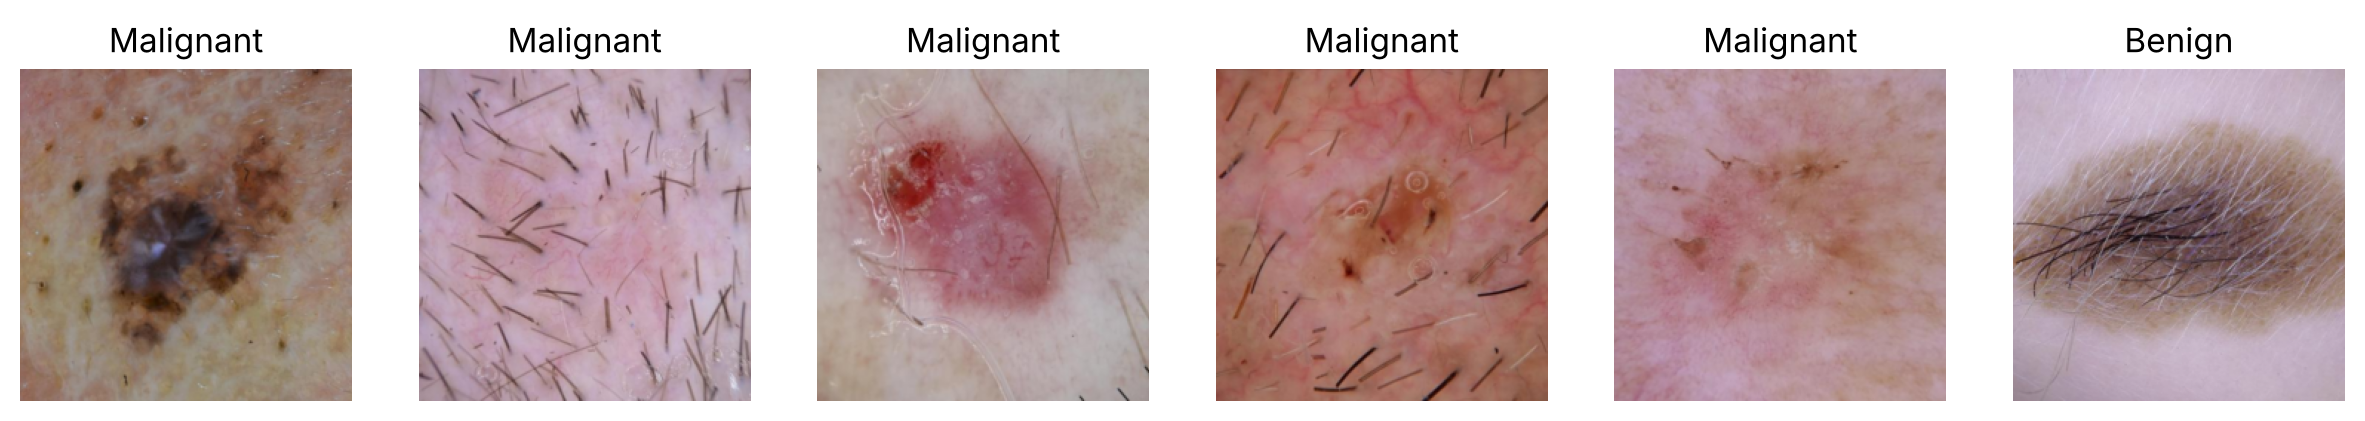

In [14]:
# PURPOSE: display the first 6 training images with their labels.
# HOW: matplotlib wants (H, W, 3), so permute moves the channels back to the end.

fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for ax, i in zip(axes, [0, 1, 2, 3, 4, 5]):
    ax.imshow(X_train[i].permute(1, 2, 0)); ax.set_title(CLASSES[y_train[i]]); ax.axis("off")

### 5. The training toolkit — normalize, augment, fit, evaluate

Four small tools that every model below will share.

#### 5.1 `prep`: normalize like ImageNet

ResNet was trained on images scaled with ImageNet's mean and standard deviation, so it must receive the same scale. We use it for all of today's models. (Our own train statistics in `outputs/normalization.json` differ: skin images are brighter and less varied than ImageNet photos. The pretrained layers, though, expect ImageNet's scale.)

In [15]:
# PURPOSE: turn stored pixels (0-255) into what the network expects.
# HOW: uint8 -> float in [0, 1] -> subtract the mean and divide by the std, per channel.

# view(1, 3, 1, 1): one value per channel, in a shape that applies to a whole batch
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)   # ImageNet statistics
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def prep(xb):
    return (xb.to(device).float() / 255 - MEAN) / STD

# Check by hand: a red value of 200 becomes 1.31
print(((200 / 255) - 0.485) / 0.229)             # 1.31

1.3070468362017296


#### 5.2 `augment`: random flips

A lesion has no "up", so a flipped lesion keeps its diagnosis. The model sees slightly different images in each epoch (Session 3).

In [16]:
# PURPOSE: add variety to the training images without changing their labels.
# HOW: for each image, flip a coin; torch.where takes the flipped version where the coin says yes.

def augment(xb):
    n = xb.size(0)                                           # number of images in the batch
    
    # --- Coin 1: left-right flip ---
    # torch.rand gives n random numbers between 0 and 1, one per image.
    # "< 0.5" turns each number into True or False, so each image has a 50% chance.
    # Shape (n, 1, 1, 1): one decision per image, applied to all of its channels and pixels.
    # device=xb.device: create the numbers where the images are (CPU or GPU).
    flip_h = torch.rand(n, 1, 1, 1, device=xb.device) < 0.5  # one True/False per image

    # xb.flip(3) reverses dimension 3 (the width), which mirrors the images left-right.
    # torch.where(condition, a, b) chooses image by image:
    # where the condition is True it takes a (flipped), otherwise b (original).
    xb = torch.where(flip_h, xb.flip(3), xb)                 # left-right

    # --- Coin 2: up-down flip, decided independently ---
    flip_v = torch.rand(n, 1, 1, 1, device=xb.device) < 0.5

    # xb.flip(2) reverses dimension 2 (the height), which mirrors the images up-down.
    # So each image ends up in one of 4 versions: original, left-right, up-down, or both.
    # The batch shape does not change, and the labels stay the same.
    return torch.where(flip_v, xb.flip(2), xb)               # up-down

#### 5.3 `predict` and `fit`: Session 6's training loop

The same steps as Session 6: **zero_grad → forward + loss → backward → step**. The model changes, but the loop doesn't. After each epoch we measure validation macro-F1 and remember the best weights.

In [17]:
# PURPOSE: one function to predict and one to train, reused by every model below.
# HOW: batches of images go through Session 6's loop, with class weights in the loss.

from sklearn.metrics import f1_score, accuracy_score, ConfusionMatrixDisplay

# Class weights n / (3 * n_c), so mistakes on rare classes cost more: ours, from class_weights.json (train only).
# One dermoscopic image per lesion halves every count, so they equal the weights of these 3,667 images.
class_weights = load_class_weights(config.LABEL).to(device)          # tensor([1.1776, 14.0498, 0.4809])
assert torch.allclose(class_weights.cpu(), len(y_train) / (3 * torch.bincount(y_train).float()), atol=1e-3), \
    "class_weights.json does not match this split: run  python milestone1.py loaders"

# predict: evaluation mode, no gradients; take the class with the highest score, batch by batch
@torch.no_grad()
def predict(model, X, batch_size=128):
    model.eval()
    return torch.cat([model(prep(X[i:i + batch_size])).argmax(1).cpu() for i in range(0, len(X), batch_size)])

def fit(model, params, epochs, lr, batch_size=64, aug=True):
    model.to(device)
    optimizer = torch.optim.Adam(params, lr=lr)          # params: only the weights we want to train
    loss_fn = nn.CrossEntropyLoss(weight=class_weights)
    history, best = [], {"f1": -1}
    for epoch in range(epochs):
        model.train()
        t0, total = time.perf_counter(), 0.0
        order = torch.randperm(len(X_train))             # new random order in each epoch
        for i in range(0, len(X_train), batch_size):
            # Take the next batch, normalize it and (optionally) flip it
            idx = order[i:i + batch_size]
            xb, yb = prep(X_train[idx]), y_train[idx].to(device)
            if aug:
                xb = augment(xb)

            # The training step from Session 6
            optimizer.zero_grad()                        # forget the old gradients
            loss = loss_fn(model(xb), yb)                # forward + loss
            loss.backward()                              # backprop: compute the gradients
            optimizer.step()                             # update the weights
            total += loss.item() * len(idx)

        # End of the epoch: score on validation and remember the best weights so far
        f1 = f1_score(y_val, predict(model, X_val), average="macro")
        seconds = time.perf_counter() - t0               # training + validation time of this epoch
        history.append({"epoch": epoch, "train_loss": total / len(X_train), "val_f1": f1, "seconds": seconds})
        print(f"epoch {epoch}  loss {total / len(X_train):.3f}  val macro-F1 {f1:.3f}  ({seconds:.0f} s)")
        if f1 > best["f1"]:
            best = {"f1": f1, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}
    model.load_state_dict(best["state"])          # early stopping: keep the best epoch
    return pd.DataFrame(history).set_index("epoch"), best

### 6. Train the CNN from scratch

Random weights, 3,667 lesions, 10 epochs. Is that enough to learn good filters?

#### 6.1 Training

Look at the validation macro-F1 from one epoch to the next, not only at the best value.

In [18]:
# PURPOSE: train SimpleCNN from random weights, as a reference.
# HOW: call fit with all the model's weights and a learning rate of 1e-3.

torch.manual_seed(config.SEED)
scratch = SimpleCNN()
hist_scratch, best_scratch = fit(scratch, scratch.parameters(), epochs=10, lr=1e-3)
print("best epoch", best_scratch["epoch"], "val macro-F1", round(best_scratch["f1"], 3))   # class run (other split): best epoch 3, val macro-F1 0.555

epoch 0  loss 1.242  val macro-F1 0.502  (55 s)


epoch 1  loss 0.963  val macro-F1 0.409  (59 s)


epoch 2  loss 0.920  val macro-F1 0.489  (61 s)


epoch 3  loss 0.909  val macro-F1 0.436  (58 s)


epoch 4  loss 0.871  val macro-F1 0.509  (59 s)


epoch 5  loss 0.800  val macro-F1 0.503  (58 s)


epoch 6  loss 0.765  val macro-F1 0.527  (57 s)


epoch 7  loss 0.757  val macro-F1 0.489  (57 s)


epoch 8  loss 0.707  val macro-F1 0.518  (58 s)


epoch 9  loss 0.672  val macro-F1 0.531  (59 s)
best epoch 9 val macro-F1 0.531


#### 6.2 What did its first layer learn?

These are its 16 filters of 3×3×3, shown as tiny color images. Compare them with ResNet's filters in section 7.

" \nf.permute(1, 2, 0) changes each filter from (3, 3, 3) as (channels, height, width) to (height, width, channels), the order imshow expects.\nimshow then reads the three grids as the R, G and B values of an image: 3×3 pixels, each with 3 values.\nThe weights are first rescaled to [0, 1], because colors can't be negative.\n"

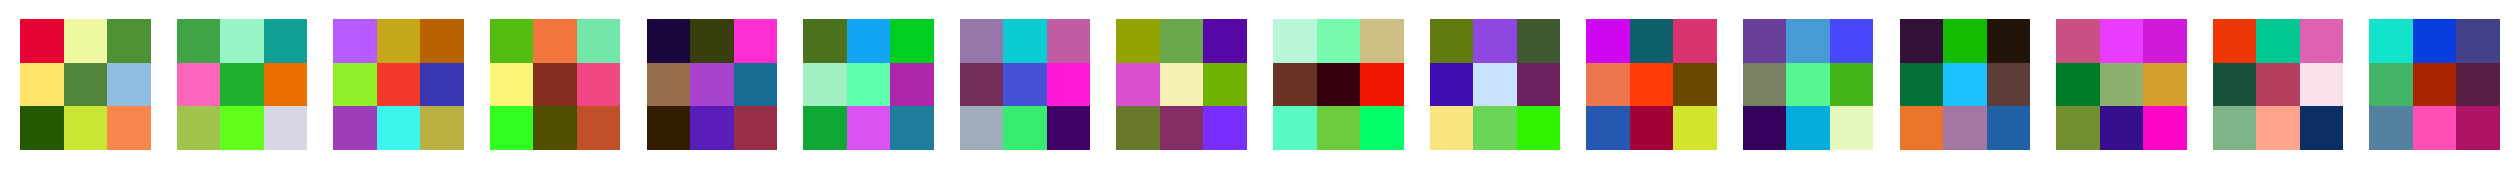

In [19]:
# PURPOSE: look inside the trained network.
# HOW: read the weights of the first conv layer and draw each filter as an image.

w = scratch.features[0].weight.detach().cpu()                       # (16, 3, 3, 3)
fig, axes = plt.subplots(1, 16, figsize=(16, 1.4))
for ax, f in zip(axes, w):
    # Weights can be negative, so rescale each filter to [0, 1] just to display it
    f = f.permute(1, 2, 0); ax.imshow((f - f.min()) / (f.max() - f.min())); ax.axis("off")
    
""" 
f.permute(1, 2, 0) changes each filter from (3, 3, 3) as (channels, height, width) to (height, width, channels), the order imshow expects.
imshow then reads the three grids as the R, G and B values of an image: 3×3 pixels, each with 3 values.
The weights are first rescaled to [0, 1], because colors can't be negative.
"""

### 7. A pretrained ResNet-18

This network learned its 11.7 million weights on 1.28 million ImageNet photos. Before using it, we look inside.

#### 7.1 Loading the network

Its last layer, `fc`, maps 512 numbers to ImageNet's 1,000 classes. The table shows how many weights each part has.

In [20]:
# PURPOSE: load ResNet-18 with its ImageNet weights and see how it is built.
# HOW: torchvision downloads the weights; named_children lists the main blocks.

from torchvision.models import resnet18, ResNet18_Weights

resnet = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)       # downloads ~45 MB the first time
print(resnet.fc)                                                # Linear(in_features=512, out_features=1000)
print(f"{count(resnet):,} parameters")                          # 11,689,512
for name, child in resnet.named_children():
    print(f"{name:8s} {count(child):>10,}")

Linear(in_features=512, out_features=1000, bias=True)
11,689,512 parameters
conv1         9,408
bn1             128
relu              0
maxpool           0
layer1      147,968
layer2      525,568
layer3    2,099,712
layer4    8,393,728
avgpool           0
fc          513,000


#### 7.2 Its first layer: 64 filters learned on ImageNet

Nobody designed these. Look for edges at different angles and for color blobs, and compare them with our from-scratch filters.

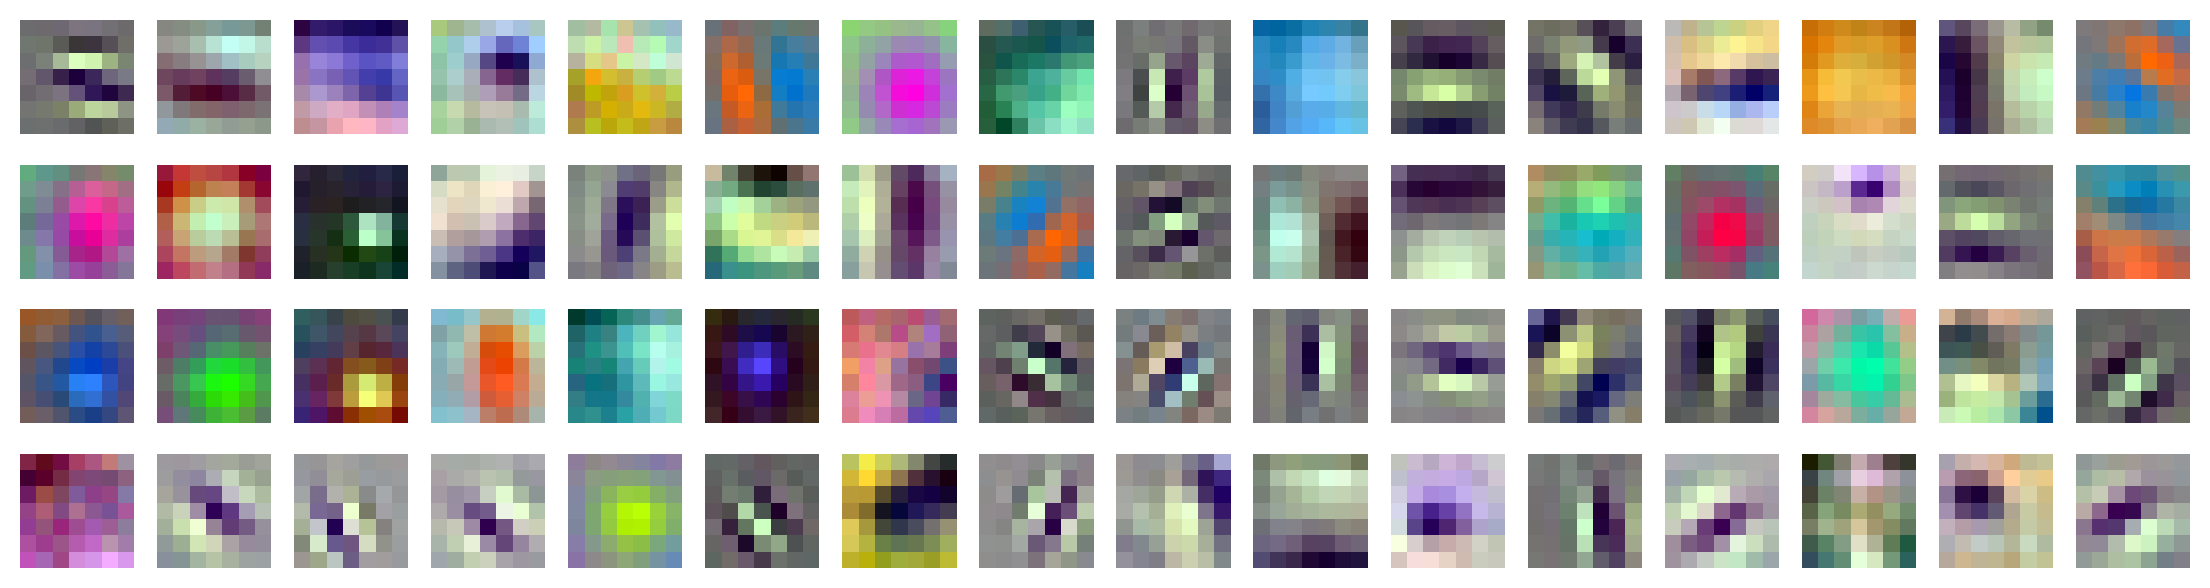

In [21]:
# PURPOSE: see what a well-trained first layer looks like.
# HOW: same as cell 6.2, now with 64 filters of 7x7x3.

w = resnet.conv1.weight.detach()                                 # (64, 3, 7, 7)
fig, axes = plt.subplots(4, 16, figsize=(14, 3.6))
for ax, f in zip(axes.ravel(), w):
    f = f.permute(1, 2, 0); ax.imshow((f - f.min()) / (f.max() - f.min())); ax.axis("off")

#### 7.3 One lesion through the network

We show one feature map after each of the four stages. As we go deeper, the maps get smaller and coarser, and there are more of them.

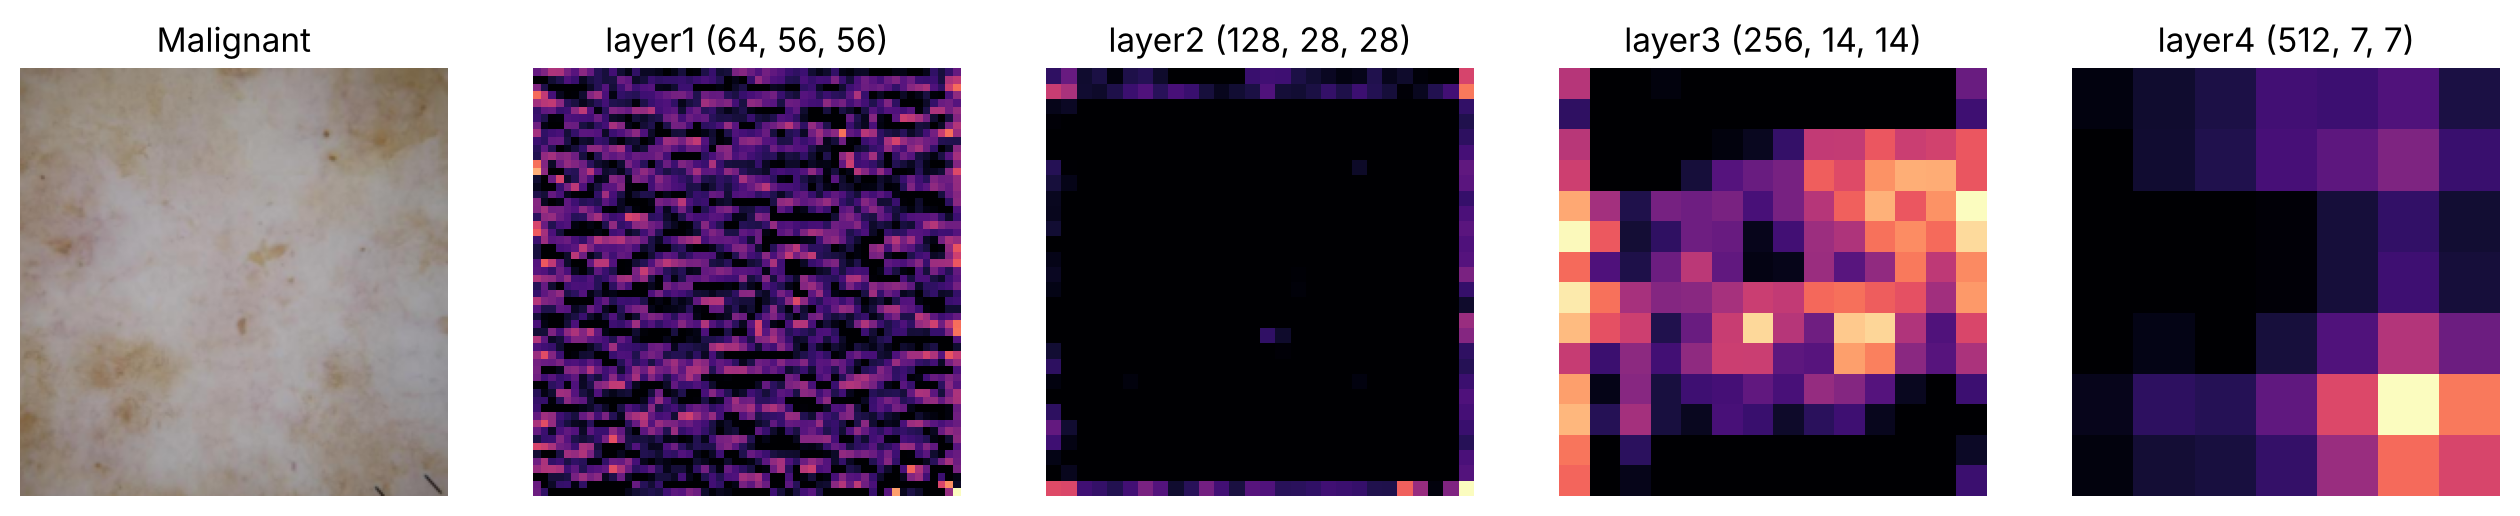

In [22]:
# PURPOSE: see the feature hierarchy on a real lesion.
# HOW: run the network stage by stage and draw the most varied map of each stage.

x = prep(X_val[:1])                                              # the first validation image
resnet.to(device).eval()
with torch.no_grad():
    # The layers that come before layer1
    h = resnet.maxpool(resnet.relu(resnet.bn1(resnet.conv1(x))))
    fig, axes = plt.subplots(1, 5, figsize=(16, 3.2))
    axes[0].imshow(X_val[0].permute(1, 2, 0)); axes[0].set_title(CLASSES[y_val[0]]); axes[0].axis("off")
    for ax, name in zip(axes[1:], ["layer1", "layer2", "layer3", "layer4"]):
        h = getattr(resnet, name)(h)                             # run the next stage
        k = h[0].flatten(1).std(1).argmax()                      # the map with the largest variation
        ax.imshow(h[0, k].cpu(), cmap="magma"); ax.set_title(f"{name} {tuple(h.shape[1:])}"); ax.axis("off")

### 8. Feature extraction — 512 learned numbers instead of our 33

**Strategy 1: freeze the backbone.** ResNet-18 becomes a feature extractor, and only a new last layer is trained.

#### 8.1 Turning each lesion into 512 numbers

We replace the last layer with `nn.Identity()`, which does nothing, so the network outputs its 512 internal numbers. It's Session 5's idea of a feature vector, but these numbers were learned, not designed. Since the backbone never changes, we compute them only once.

In [23]:
# PURPOSE: compute a 512-number description of every lesion.
# HOW: remove the head, then run all the images through the network without gradients.

resnet.fc = nn.Identity()
resnet.eval()

@torch.no_grad()
def embed(X, batch_size=128):
    return torch.cat([resnet(prep(X[i:i + batch_size])).cpu() for i in range(0, len(X), batch_size)])

t0 = time.perf_counter()
F_train, F_val, F_test = embed(X_train), embed(X_val), embed(X_test)
print(F_train.shape, f"{time.perf_counter() - t0:.0f} s")       # torch.Size([3667, 512])

torch.Size([3667, 512]) 121 s


#### 8.2 Training only a new last layer

From here it's a tabular problem, like Session 6: 512 numbers per lesion and 3 classes. The new layer has only 1,539 weights. The number to beat is our classical baseline on the same lesions: hand-crafted features of the dermoscopic image + random forest, **0.621** validation macro-F1 (the class forest scored 0.534 on its own split).

In [24]:
# PURPOSE: train the new head on the 512 numbers and score it on validation.
# HOW: one nn.Linear(512, 3), and Session 6's loop over batches of features.

from torch.utils.data import TensorDataset

torch.manual_seed(config.SEED)
head = nn.Linear(512, 3).to(device)                       # 512 x 3 weights + 3 biases = 1,539
optimizer = torch.optim.Adam(head.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss(weight=class_weights)
loader = DataLoader(TensorDataset(F_train, y_train), batch_size=64, shuffle=True)
for epoch in range(25):
    for fb, yb in loader:
        optimizer.zero_grad()
        loss = loss_fn(head(fb.to(device)), yb.to(device))
        loss.backward()
        optimizer.step()

# Score on validation
with torch.no_grad():
    head_val_f1 = f1_score(y_val, head(F_val.to(device)).argmax(1).cpu(), average="macro")
print(f"frozen ResNet-18 + linear head: val macro-F1 = {head_val_f1:.3f}")      # class run (other split): 0.632

frozen ResNet-18 + linear head: val macro-F1 = 0.567


#### 8.3 Where are the errors?

Rows are the truth and columns are the prediction. Look at the small Indeterminate row: our validation set has only 18 Indeterminate lesions, and our dermoscopic-feature forest found 6 of them.

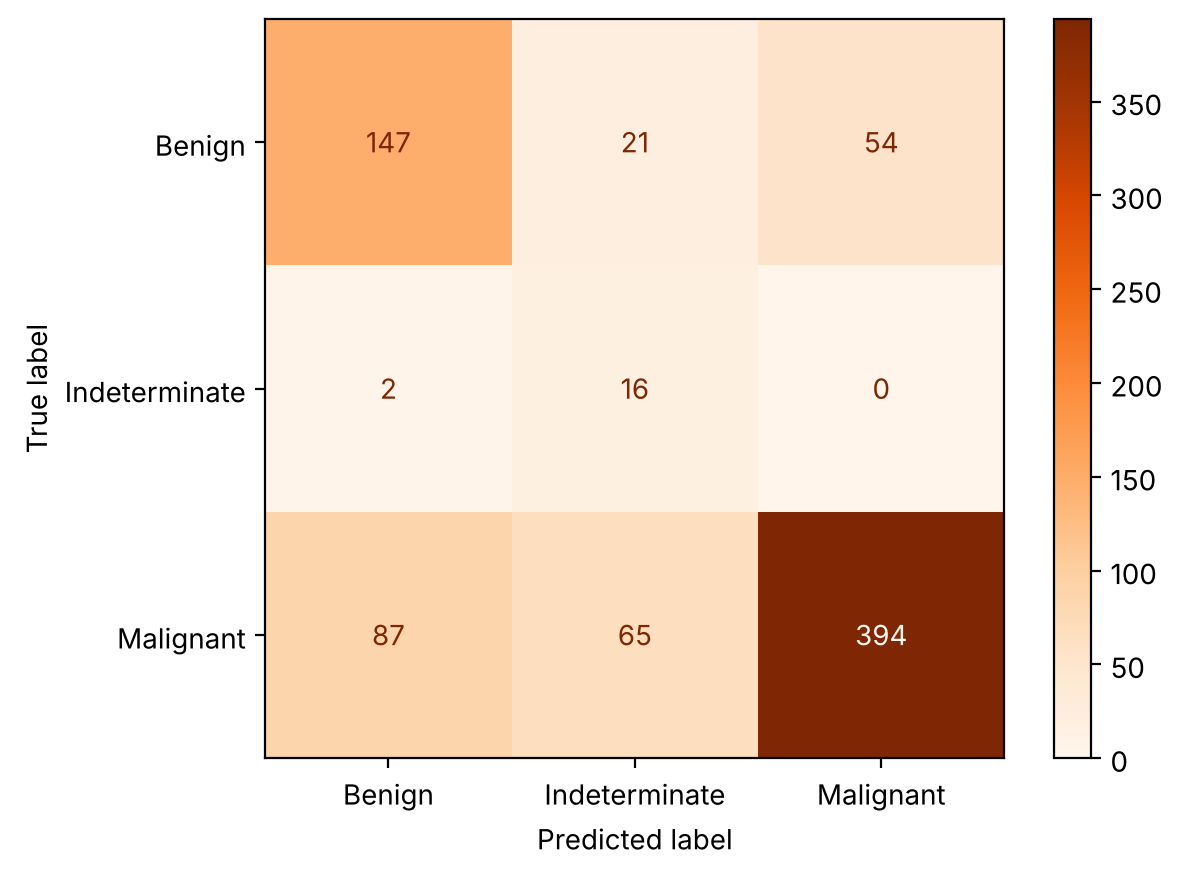

In [25]:
# PURPOSE: see the errors per class, which a single score hides.
# HOW: predict on validation and draw the confusion matrix.

with torch.no_grad():
    head_val_pred = head(F_val.to(device)).argmax(1).cpu()
ConfusionMatrixDisplay.from_predictions(y_val, head_val_pred, display_labels=CLASSES, cmap="Oranges");
# Indeterminate row: how many of the 18 are found? (our dermoscopic-feature forest: 6)

### 9. Partial fine-tuning — unfreeze `layer4`

**Strategy 2: let the last block adapt to skin lesions.** The earlier blocks stay frozen.

#### 9.1 Choosing what to train

We take a fresh pretrained ResNet with a new head. `requires_grad = False` freezes a weight: PyTorch computes no gradient for it, so it never changes.

In [26]:
# PURPOSE: freeze everything except layer4 and the new head.
# HOW: loop over all the weights and switch requires_grad according to the layer's name.

torch.manual_seed(config.SEED)
model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
model.fc = nn.Linear(512, 3)                                     # new head: 3 classes
for name, p in model.named_parameters():
    p.requires_grad = name.startswith("layer4") or name.startswith("fc")

# Keep the list of weights that will be trained, and count them
trainable = [p for p in model.parameters() if p.requires_grad]
print(f"training {sum(p.numel() for p in trainable):,} of {count(model):,} parameters")

training 8,395,267 of 11,178,051 parameters


#### 9.2 Fine-tuning

We use a smaller learning rate (1e-4): the pretrained weights are already good, so we only nudge them. Flips are on. Now the images must go through the network in every epoch, so this is the slowest step so far.

In [27]:
# PURPOSE: let layer4 adapt to dermoscopy.
# HOW: the same fit function as in section 6, given only the trainable weights.

hist_ft, best_ft = fit(model, trainable, epochs=6, lr=1e-4)
print("best epoch", best_ft["epoch"], "val macro-F1", round(best_ft["f1"], 3))     # class run (other split): best epoch 1, val macro-F1 0.614

epoch 0  loss 0.869  val macro-F1 0.568  (125 s)


epoch 1  loss 0.584  val macro-F1 0.606  (129 s)


epoch 2  loss 0.473  val macro-F1 0.681  (119 s)


epoch 3  loss 0.386  val macro-F1 0.650  (120 s)


epoch 4  loss 0.371  val macro-F1 0.644  (126 s)


epoch 5  loss 0.285  val macro-F1 0.650  (135 s)
best epoch 2 val macro-F1 0.681


#### 9.3 Where are the errors now?

Compare with the matrix of the frozen model in 8.3. With only 786 validation lesions, small differences can be noise.

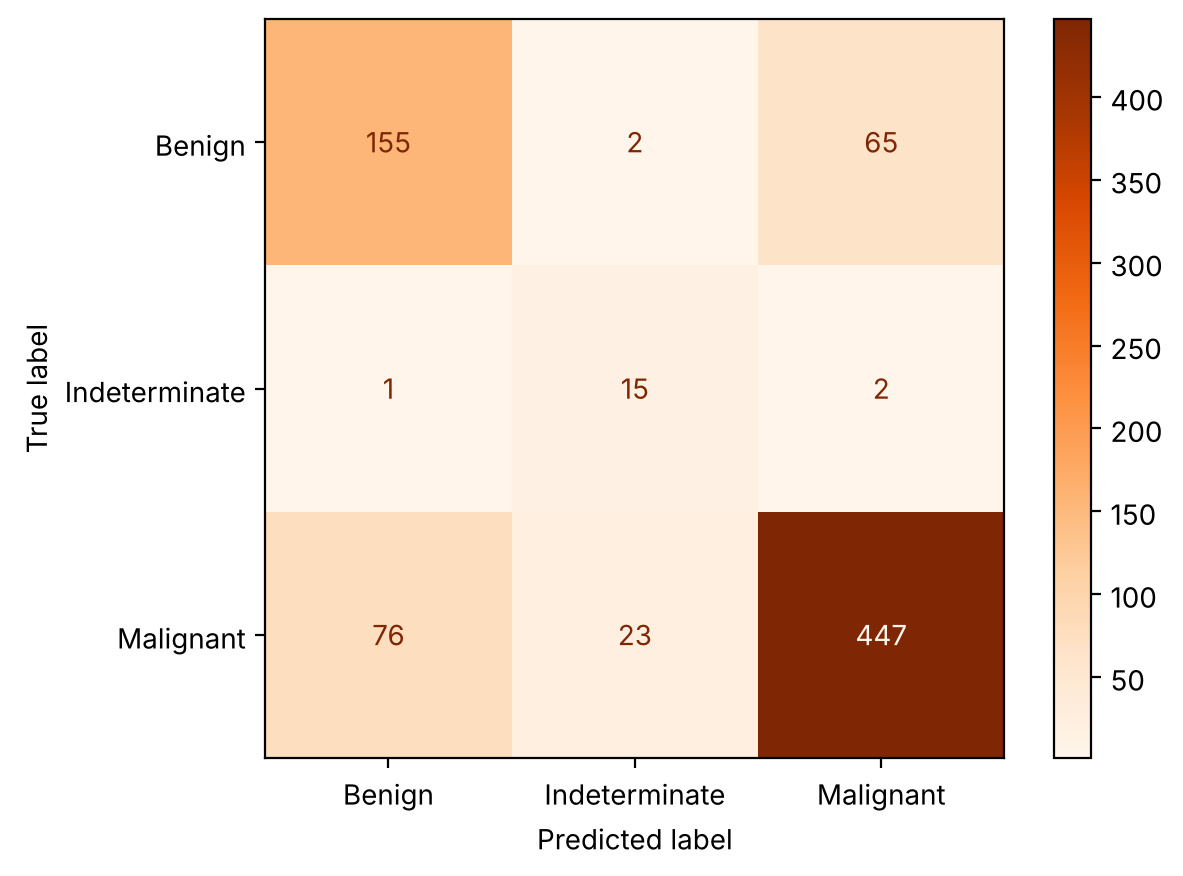

In [28]:
# PURPOSE: compare the errors of the fine-tuned model with the frozen one.
# HOW: same as cell 8.3; predict() already restored the model's best epoch.

ConfusionMatrixDisplay.from_predictions(y_val, predict(model, X_val), display_labels=CLASSES, cmap="Oranges");

### 10. Scoreboard — same validation lesions, same metric

The classical rows come from our classical baseline (`outputs/classical_baseline/`) when its files are in the repo. The CNNs see only the dermoscopic image; the final classical model also used the clinical image and the metadata. The test set stays closed.

In [29]:
# PURPOSE: put every model side by side on the 786 validation lesions.
# HOW: collect each model's best validation macro-F1, add the classical baseline if its results are in outputs/.

OUT = config.OUTPUT_DIR / "session7"                    # small result files, fine to commit
OUT.mkdir(parents=True, exist_ok=True)

scoreboard = {"CNN from scratch": best_scratch["f1"],
              "ResNet-18 frozen + linear head": head_val_f1,
              "ResNet-18 fine-tuned layer4": best_ft["f1"]}

baseline_dir = config.OUTPUT_DIR / "classical_baseline"
if (baseline_dir / "comparison.csv").exists():
    comp = pd.read_csv(baseline_dir / "comparison.csv").set_index(["feature_set", "model"])
    scoreboard["classical: dermoscopic features + RandomForest"] = comp.loc[("derm C+T+S", "RandomForest"), "val_macro_f1"]
    final = json.loads((baseline_dir / "best_config.json").read_text())
    scoreboard[f"classical final: {final['feature_set']} + {final['model']}"] = final["val_macro_f1"]
else:
    print(f"no classical baseline results in {baseline_dir}: showing the CNNs only")

def show_scoreboard():
    board = pd.Series(scoreboard, name="val macro-F1").sort_values(ascending=False).round(3).to_frame()
    board.to_csv(OUT / "scoreboard_val.csv")
    return board

show_scoreboard()

,val macro-F1
ResNet-18 fine-tuned layer4,0.681
classical: dermoscopic features + RandomForest,0.621
classical final: both C+T+S+meta + LogReg,0.572
ResNet-18 frozen + linear head,0.567
CNN from scratch,0.531


### 11. Mini challenge — unfreeze more

Start from a fresh pretrained ResNet-18 and also unfreeze `layer3` (train `layer3` + `layer4` + `fc`) with `lr=1e-4`.

Note the number of trainable parameters, the seconds per epoch and the best **validation** macro-F1. Compare with `layer4` only: was it worth it? The test set stays closed.

In [30]:
# PURPOSE: does unfreezing layer3 as well pay off?
# HOW: same as 9.1 and 9.2 with a fresh pretrained ResNet, now training layer3 + layer4 + fc.

torch.manual_seed(config.SEED)
model34 = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
model34.fc = nn.Linear(512, 3)
for name, p in model34.named_parameters():
    p.requires_grad = name.startswith(("layer3", "layer4", "fc"))

trainable34 = [p for p in model34.parameters() if p.requires_grad]
print(f"training {sum(p.numel() for p in trainable34):,} of {count(model34):,} parameters")   # layer4 + fc: 8,395,267

hist_ft34, best_ft34 = fit(model34, trainable34, epochs=6, lr=1e-4)    # seconds per epoch: see the log
print("best epoch", best_ft34["epoch"], "val macro-F1", round(best_ft34["f1"], 3))

training 10,494,979 of 11,178,051 parameters


epoch 0  loss 0.861  val macro-F1 0.561  (159 s)


epoch 1  loss 0.566  val macro-F1 0.626  (155 s)


epoch 2  loss 0.456  val macro-F1 0.676  (149 s)


epoch 3  loss 0.365  val macro-F1 0.605  (153 s)


epoch 4  loss 0.351  val macro-F1 0.627  (154 s)


epoch 5  loss 0.264  val macro-F1 0.632  (160 s)
best epoch 2 val macro-F1 0.676


In [31]:
# PURPOSE: compare layer3 + layer4 with layer4 only, on validation (test still closed).
# HOW: add the new row to the scoreboard of section 10.

scoreboard["ResNet-18 fine-tuned layer3 + layer4"] = best_ft34["f1"]
show_scoreboard()

,val macro-F1
ResNet-18 fine-tuned layer4,0.681
ResNet-18 fine-tuned layer3 + layer4,0.676
classical: dermoscopic features + RandomForest,0.621
classical final: both C+T+S+meta + LogReg,0.572
ResNet-18 frozen + linear head,0.567
CNN from scratch,0.531


#### 11.1 Mini challenge: the three measurements

Trainable weights, seconds per epoch (median over the 6 epochs, on the machine that ran this notebook: see the device printed in 0.1) and best **validation** macro-F1.

In [32]:
# PURPOSE: put the three numbers the mini challenge asks for side by side.
# HOW: count the trainable weights, take the median epoch time from fit()'s history and the best validation macro-F1.

def run_summary(name, params, hist, best):
    return {"run": name, "trainable weights": sum(p.numel() for p in params),
            "s / epoch": round(hist["seconds"].median()), "best val macro-F1": round(best["f1"], 3),
            "best epoch": best["epoch"]}

challenge = pd.DataFrame([run_summary("layer4 + fc", trainable, hist_ft, best_ft),
                          run_summary("layer3 + layer4 + fc", trainable34, hist_ft34, best_ft34)]).set_index("run")
challenge

,trainable weights,s / epoch,best val macro-F1,best epoch
run,,,,
layer4 + fc,8395267,125,0.681,2
layer3 + layer4 + fc,10494979,155,0.676,2


**Worth it? No, not on our data.** Unfreezing `layer3` as well trains 2.1 M more weights (10,494,979 instead of 8,395,267, +25%) and makes every epoch about 24% slower (155 s instead of 125 s on this 2-core CPU), but the best validation macro-F1 does not improve: 0.676 against 0.681 for `layer4` alone. That difference is far smaller than the noise of 786 validation lesions with only 18 Indeterminate ones. Both runs peak at epoch 2 (their third epoch) and then fall back while the training loss keeps dropping, so the extra capacity mainly lets the network fit the 3,667 training lesions faster. With moderate data like ours, `layer4` + `fc` is the better trade, as the slides suggest. The decision uses validation only; the test set stays closed until 12.2.

### 12. Homework before Session 8

1. Finalise the scoreboard: Sessions 5 to 7, validation **and** test macro-F1, and our best model with its number (12.2 and 12.3).
2. Read about EfficientNet or DenseNet: one sentence on how it differs from ResNet (12.4).
3. Optional: fine-tune the whole network, strategy 3 (12.1).

#### 12.1 Optional: fine-tune the whole network (strategy 3)

Every weight trains, including `conv1` and `layer1`, which hold the generic edge and colour detectors. Same recipe as sections 9 and 11 (fresh pretrained ResNet-18, lr = 1e-4, flips, 6 epochs, best validation epoch kept), so the only change is how much is unfrozen.

In [33]:
# PURPOSE: homework 3 (optional), strategy 3: let every layer adapt to dermoscopy.
# HOW: same as 9.1 and 9.2 with a fresh pretrained ResNet-18, but nothing is frozen.

torch.manual_seed(config.SEED)
model_full = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
model_full.fc = nn.Linear(512, 3)
trainable_full = [p for p in model_full.parameters() if p.requires_grad]      # all of them
print(f"training {sum(p.numel() for p in trainable_full):,} of {count(model_full):,} parameters")   # 11,178,051

hist_full, best_full = fit(model_full, trainable_full, epochs=6, lr=1e-4)     # same epochs and lr as 9 and 11
print("best epoch", best_full["epoch"], "val macro-F1", round(best_full["f1"], 3))

training 11,178,051 of 11,178,051 parameters


epoch 0  loss 0.865  val macro-F1 0.538  (237 s)


epoch 1  loss 0.585  val macro-F1 0.654  (245 s)


epoch 2  loss 0.468  val macro-F1 0.682  (248 s)


epoch 3  loss 0.400  val macro-F1 0.565  (251 s)


epoch 4  loss 0.363  val macro-F1 0.624  (244 s)


epoch 5  loss 0.298  val macro-F1 0.646  (242 s)
best epoch 2 val macro-F1 0.682


In [34]:
# PURPOSE: compare the three strategies of the slides (plus the mini challenge) on validation.
# HOW: one row per strategy with the mini challenge's three numbers; the frozen model trains only its head,
#      on features computed once in 8.1, so it has no comparable time per epoch.

strategies = pd.DataFrame([
    {"run": "1. frozen backbone + linear head", "trainable weights": count(head), "s / epoch": None,
     "best val macro-F1": round(head_val_f1, 3), "best epoch": None},
    run_summary("2. layer4 + fc", trainable, hist_ft, best_ft),
    run_summary("2b. layer3 + layer4 + fc (mini challenge)", trainable34, hist_ft34, best_ft34),
    run_summary("3. whole network", trainable_full, hist_full, best_full),
]).set_index("run").astype({"s / epoch": "Int64", "best epoch": "Int64"})
strategies.to_csv(OUT / "finetuning_strategies.csv")
strategies

,trainable weights,s / epoch,best val macro-F1,best epoch
run,,,,
1. frozen backbone + linear head,1539,<NA>,0.567,<NA>
2. layer4 + fc,8395267,125,0.681,2
2b. layer3 + layer4 + fc (mini challenge),10494979,155,0.676,2
3. whole network,11178051,244,0.682,2


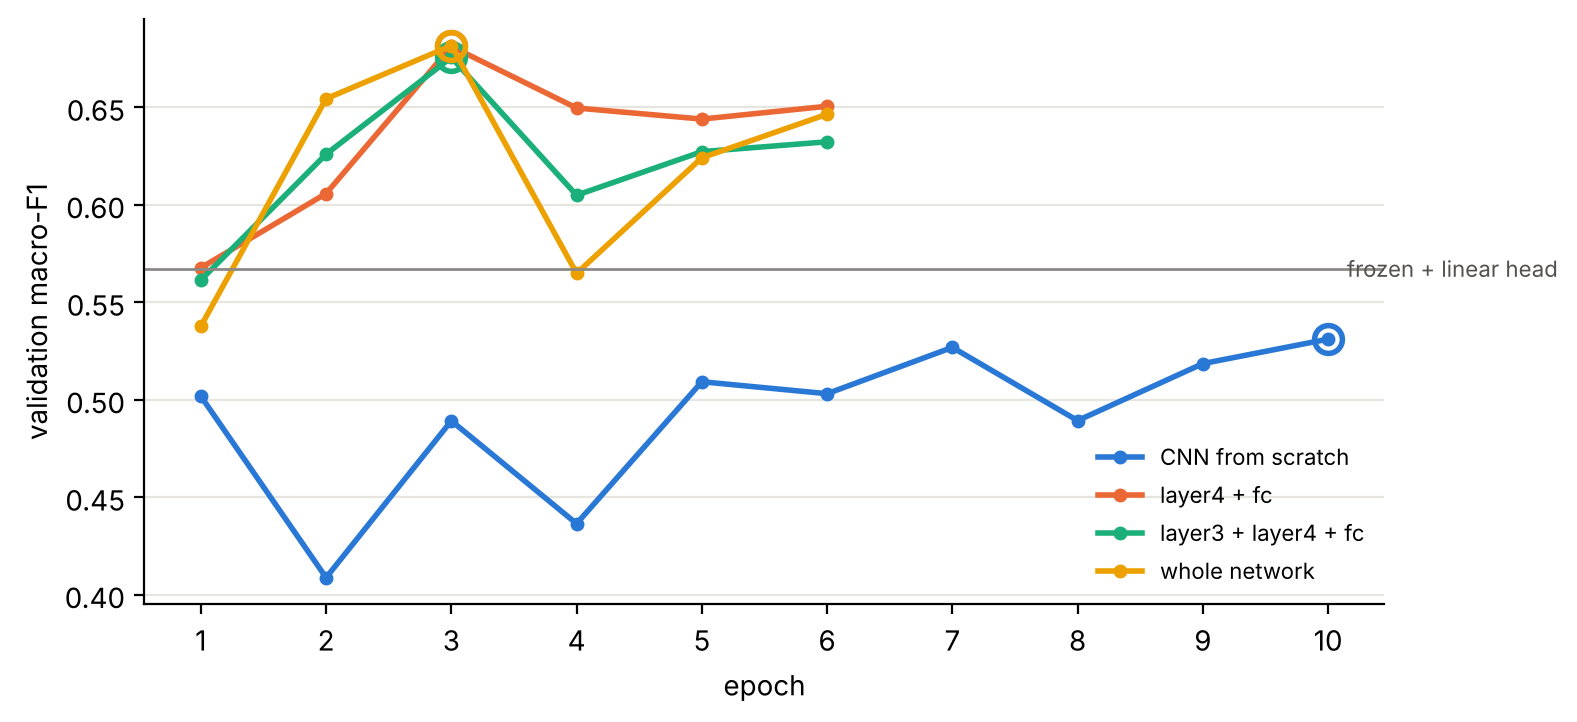

In [35]:
# PURPOSE: look at validation macro-F1 epoch by epoch, not only at its best value.
# HOW: one line per network trained with fit(); the ring marks the epoch whose weights were kept.

FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
runs = {"CNN from scratch": (hist_scratch, best_scratch), "layer4 + fc": (hist_ft, best_ft),
        "layer3 + layer4 + fc": (hist_ft34, best_ft34), "whole network": (hist_full, best_full)}
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]          # validated colour-blind-safe order
fig, ax = plt.subplots(figsize=(8, 3.8))
for (name, (hist, best)), c in zip(runs.items(), colors):
    ax.plot(hist.index + 1, hist["val_f1"], color=c, lw=2, marker="o", ms=4, label=name)
    ax.plot(best["epoch"] + 1, best["f1"], "o", ms=10, mfc="none", mec=c, mew=2)
ax.axhline(head_val_f1, color="#8a8984", lw=1)
ax.text(10.1, head_val_f1, " frozen + linear head", va="center", fontsize=8, color="#52514e")
ax.set_xlabel("epoch"); ax.set_ylabel("validation macro-F1"); ax.set_xticks(range(1, 11))
ax.grid(axis="y", color="#e6e5e0", lw=0.8); ax.spines[["top", "right"]].set_visible(False)
ax.legend(fontsize=8, frameon=False, loc="lower right")
fig.savefig(FIG / "val_f1_per_epoch.png", dpi=150, bbox_inches="tight")

**Strategy 3 does not pay off either.** Training all 11.2 M weights takes about twice as long per epoch as `layer4` alone (244 s against 125 s) for a validation macro-F1 of 0.682 against 0.681, a tie. The curves show why unfreezing more does not help here: every fine-tuned run peaks at its third epoch and then drops, and the whole network is the least stable (it falls to 0.565 at its fourth epoch). The frozen backbone (0.567) shows that ImageNet features need some adaptation to beat our handcrafted features, and the CNN from scratch (0.531, best at its last epoch) shows what learning every filter from 3,667 lesions costs. On data of our size, fine-tuning `layer4` gives nearly all of the gain for half the cost of the whole network.

#### 12.2 The final scoreboard: Sessions 5 to 7, validation and test

Rules, the same for every row:

* **Same lesions, same metric.** The 786 validation and 787 test lesions of our Milestone 1 split, scored per lesion with macro-F1 (Benign, Indeterminate and Malignant count equally).
* **Every choice on validation.** Hyper-parameters, the best epoch and the best model are all picked on validation, so the validation column is slightly optimistic. The **test set is opened once, here**, after every choice is made: the test column is the honest estimate.
* **Session 5 rows** are our classical models refitted on train with exactly the hyper-parameters tuned in Session 5 (`outputs/classical_baseline/comparison.csv`); the code checks that their validation scores match Session 5.
* **Session 6 rows** use the class's MLP recipe (one hidden layer of 64 ReLUs, Adam 1e-3, 50 epochs, batch 64, class weights), retrained on our split so they can sit on this board, and like `fit()` they keep their best validation epoch.
* Test macro-F1 comes with a 95% interval from 2,000 stratified bootstrap resamples of the test lesions: with only 18 Indeterminate test lesions, macro-F1 moves a lot with a few of them.

In [36]:
# PURPOSE: Session 5 rows with a test score: our classical models, refitted exactly as tuned in Session 5.
# HOW: rebuild the lesion feature table from our saved features, refit on train with the hyper-parameters in
#      comparison.csv, check that validation matches Session 5, then predict the test lesions.

import warnings
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from shared import classical

images = pd.concat([pd.read_csv(config.SPLITS_DIR / f"{s}.csv").assign(split=s) for s in ("train", "val", "test")],
                   ignore_index=True)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", pd.errors.PerformanceWarning)
    lesion_table = classical.lesion_feature_table(pd.read_csv(config.IMAGE_FEATURES_CSV, index_col="isic_id"),
                                                  images).set_index("lesion_id")

# The same lesions in the same order as the CNN tensors, so every model is scored on identical rows
rows = {"train": lesion_table.loc[train_df["lesion_id"]], "val": lesion_table.loc[val_df["lesion_id"]],
        "test": lesion_table.loc[test_df["lesion_id"]]}
for name, y in [("train", y_train), ("val", y_val), ("test", y_test)]:
    assert (rows[name][config.LABEL].map(to_int).to_numpy() == y.numpy()).all(), name

entries = []    # one entry per model: who it is, and its validation and test predictions

def add(session, name, inputs, weights, val_pred, test_pred):
    entries.append({"session": session, "model": name, "input": inputs, "trainable weights": weights,
                    "val_pred": torch.as_tensor(val_pred).cpu(), "test_pred": torch.as_tensor(test_pred).cpu()})

comparison = pd.read_csv(config.BASELINE_DIR / "comparison.csv")
real = comparison[comparison["feature_set"] != "none"]

def add_classical(name, inputs, feature_set, model_name):
    row = real[(real["feature_set"] == feature_set) & (real["model"] == model_name)].iloc[0]
    pipeline, _ = classical.model_grid()[model_name]
    params = {f"model__{k}": v for k, v in json.loads(row["params"]).items()}
    cols = classical.feature_set_columns(lesion_table, feature_set)
    fitted = classical.refit(pipeline, params, rows["train"][cols], y_train.numpy())
    val_pred, test_pred = fitted.predict(rows["val"][cols]), fitted.predict(rows["test"][cols])
    assert abs(f1_score(y_val, val_pred, average="macro") - row["val_macro_f1"]) < 1e-9, "differs from Session 5"
    add("5", name, inputs, None, val_pred, test_pred)
    print(f"{name}: {feature_set} + {model_name} {json.loads(row['params'])}, val macro-F1 {row['val_macro_f1']:.3f}")

# Same input as today's CNNs: the dermoscopic image only
add_classical("Random forest", "derm image, 131 features", "derm C+T+S", "RandomForest")
# The model Session 5 chose (on validation balanced accuracy) and reported
add_classical("Logistic regression (Session 5 choice)", "both images + metadata, 269 features",
              "both C+T+S+meta", "LogReg")
# The classical configuration with the best validation macro-F1, this board's metric
best_cfg = real.loc[real["val_macro_f1"].idxmax()]
add_classical(f"{best_cfg['model']} (best Session 5 macro-F1)", "both images + metadata, 269 features",
              best_cfg["feature_set"], best_cfg["model"])

Random forest: derm C+T+S + RandomForest {'max_depth': None, 'min_samples_leaf': 10}, val macro-F1 0.621
Logistic regression (Session 5 choice): both C+T+S+meta + LogReg {'C': 0.01}, val macro-F1 0.572


GradBoost (best Session 5 macro-F1): both C+T+S+meta + GradBoost {'learning_rate': 0.05, 'max_leaf_nodes': 15}, val macro-F1 0.667


In [37]:
# PURPOSE: Session 6 rows on our split: the class MLP recipe, on features and on flattened pixels.
# HOW: (a) our 131 dermoscopic features, standardised with train statistics;
#      (b) raw pixels: each cached 224x224 crop averaged down to 32x32 and flattened (3,072 numbers).

def fit_mlp(X_tr, X_va, hidden=64, epochs=50, lr=1e-3, batch_size=64):
    torch.manual_seed(config.SEED)
    net = nn.Sequential(nn.Linear(X_tr.shape[1], hidden), nn.ReLU(), nn.Linear(hidden, 3))
    optimizer = torch.optim.Adam(net.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights.cpu())
    loader = DataLoader(TensorDataset(X_tr, y_train), batch_size=batch_size, shuffle=True)
    best = {"f1": -1}
    for epoch in range(epochs):
        net.train()
        for xb, yb in loader:
            optimizer.zero_grad()
            loss_fn(net(xb), yb).backward()
            optimizer.step()
        net.eval()
        with torch.no_grad():
            f1 = f1_score(y_val, net(X_va).argmax(1), average="macro")
        if f1 > best["f1"]:                                  # keep the best validation epoch, like fit()
            best = {"f1": f1, "epoch": epoch, "state": copy.deepcopy(net.state_dict())}
    net.load_state_dict(best["state"])
    return net, best

def add_mlp(name, inputs, X):
    net, best = fit_mlp(X["train"], X["val"])
    with torch.no_grad():
        val_pred, test_pred = net(X["val"]).argmax(1), net(X["test"]).argmax(1)
    add("6", name, inputs, count(net), val_pred, test_pred)
    print(f"{name}: {count(net):,} weights, best epoch {best['epoch']}, val macro-F1 {best['f1']:.3f}")

def standardise(parts):
    """Fit the scaler on train only (no leak), apply it to every split, return float tensors."""
    scaler = StandardScaler().fit(parts["train"])
    return {s: torch.tensor(scaler.transform(parts[s]), dtype=torch.float32) for s in parts}

# (a) handcrafted features: the median imputer is a no-op here (no missing values) but keeps Session 5's pipeline
cols = classical.feature_set_columns(lesion_table, "derm C+T+S")
imputer = SimpleImputer(strategy="median").fit(rows["train"][cols])
add_mlp("MLP on handcrafted features", "derm image, 131 features",
        standardise({s: imputer.transform(rows[s][cols]) for s in rows}))

# (b) raw pixels: 224x224 -> 32x32 by averaging 7x7 blocks, then one long list per image (layout lost)
def pixels32(X, batch=256):
    return torch.cat([F.interpolate(X[i:i + batch].float() / 255, size=(32, 32), mode="area").flatten(1)
                      for i in range(0, len(X), batch)]).numpy()

add_mlp("MLP on raw pixels", "derm image, 32x32 pixels (3,072)",
        standardise({"train": pixels32(X_train), "val": pixels32(X_val), "test": pixels32(X_test)}))

MLP on handcrafted features: 8,643 weights, best epoch 24, val macro-F1 0.611


MLP on raw pixels: 196,867 weights, best epoch 39, val macro-F1 0.521


In [38]:
# PURPOSE: Session 7 rows: every network of today, each with the weights of its best validation epoch.
# HOW: fit() already reloaded each model's best epoch; the frozen model's head reads the 512 features of 8.1.
#      The asserts check that these are exactly the weights behind the validation scores reported above.

with torch.no_grad():
    head_val_pred = head(F_val.to(device)).argmax(1).cpu()
    head_test_pred = head(F_test.to(device)).argmax(1).cpu()

cnn_runs = [("CNN from scratch", scratch, scratch.parameters(), best_scratch),
            ("ResNet-18 fine-tuned: layer4", model, trainable, best_ft),
            ("ResNet-18 fine-tuned: layer3 + layer4", model34, trainable34, best_ft34),
            ("ResNet-18 fine-tuned: whole network", model_full, trainable_full, best_full)]
add("7", "ResNet-18 frozen + linear head", "derm image, 224x224", count(head), head_val_pred, head_test_pred)
for name, net, params, best in cnn_runs:
    val_pred = predict(net, X_val)
    assert abs(f1_score(y_val, val_pred, average="macro") - best["f1"]) < 1e-9, name
    add("7", name, "derm image, 224x224", sum(p.numel() for p in params), val_pred, predict(net, X_test))
print(len(entries), "models")

10 models


In [39]:
# PURPOSE: the final scoreboard: every model of the course on the same lesions, with the same metric.
# HOW: macro-F1 on validation (used for every choice) and on test (opened once, here),
#      plus a 95% interval for test from a stratified bootstrap of the 787 test lesions.

def test_interval(pred, n=2000, seed=config.SEED):
    rng = np.random.default_rng(seed)
    y, p = y_test.numpy(), np.asarray(pred)
    by_class = [np.flatnonzero(y == k) for k in range(len(CLASSES))]     # class counts kept in every resample
    draws = []
    for _ in range(n):
        idx = np.concatenate([rng.choice(ix, size=len(ix), replace=True) for ix in by_class])
        draws.append(f1_score(y[idx], p[idx], average="macro"))
    return np.percentile(draws, [2.5, 97.5])

# Reference row: what "always Malignant" scores (the majority class)
always_mal = to_int["Malignant"]
add("ref", "always Malignant", "none", 0, torch.full_like(y_val, always_mal), torch.full_like(y_test, always_mal))

table = []
for e in entries:
    low, high = test_interval(e["test_pred"])
    table.append({"session": e["session"], "model": e["model"], "input": e["input"],
                  "trainable weights": e["trainable weights"],
                  "val macro-F1": f1_score(y_val, e["val_pred"], average="macro"),
                  "test macro-F1": f1_score(y_test, e["test_pred"], average="macro"),
                  "test 95% CI": f"{low:.3f} to {high:.3f}"})
board = pd.DataFrame(table).sort_values("val macro-F1", ascending=False).reset_index(drop=True)
board.index += 1
board.to_csv(OUT / "scoreboard.csv", index_label="rank")

# The same table as Markdown, readable on GitHub
text = board.assign(**{"trainable weights": board["trainable weights"].map(lambda v: "" if pd.isna(v) else f"{v:,.0f}"),
                       "val macro-F1": board["val macro-F1"].map("{:.3f}".format),
                       "test macro-F1": board["test macro-F1"].map("{:.3f}".format)})
lines = ["| rank | " + " | ".join(text.columns) + " |", "|---" * (len(text.columns) + 1) + "|"]
lines += [f"| {rank} | " + " | ".join(map(str, row)) + " |" for rank, row in zip(text.index, text.itertuples(index=False))]
(OUT / "scoreboard.md").write_text(
    "# Final scoreboard, Sessions 5 to 7 (written by session7_cnns.ipynb, section 12.2)\n\n"
    "Macro-F1 per lesion on the 786 validation and 787 test lesions of the Milestone 1 split. Every choice was made "
    "on validation; test was scored once. 95% CI: stratified bootstrap of the test lesions, 2,000 resamples.\n\n"
    + "\n".join(lines) + "\n")

# Every model's predictions, so any number on the board can be re-checked without re-training
for split, ids, y in [("val", val_df["lesion_id"], y_val), ("test", test_df["lesion_id"], y_test)]:
    pd.DataFrame({"lesion_id": ids, "true": [CLASSES[i] for i in y]}
                 | {e["model"]: [CLASSES[i] for i in e[f"{split}_pred"]] for e in entries}
                 ).to_csv(OUT / f"predictions_{split}.csv", index=False)

board.style.format({"val macro-F1": "{:.3f}", "test macro-F1": "{:.3f}", "trainable weights": "{:,.0f}"},
                   na_rep="")

,session,model,input,trainable weights,val macro-F1,test macro-F1,test 95% CI
1,7,ResNet-18 fine-tuned: whole network,"derm image, 224x224","11,178,051",0.682,0.597,0.549 to 0.645
2,7,ResNet-18 fine-tuned: layer4,"derm image, 224x224","8,395,267",0.681,0.634,0.584 to 0.682
3,7,ResNet-18 fine-tuned: layer3 + layer4,"derm image, 224x224","10,494,979",0.676,0.627,0.570 to 0.683
4,5,GradBoost (best Session 5 macro-F1),"both images + metadata, 269 features",,0.667,0.599,0.544 to 0.653
5,5,Random forest,"derm image, 131 features",,0.621,0.574,0.504 to 0.643
6,6,MLP on handcrafted features,"derm image, 131 features","8,643",0.611,0.561,0.514 to 0.608
7,5,Logistic regression (Session 5 choice),"both images + metadata, 269 features",,0.572,0.532,0.499 to 0.562
8,7,ResNet-18 frozen + linear head,"derm image, 224x224","1,539",0.567,0.537,0.507 to 0.568
9,7,CNN from scratch,"derm image, 224x224","306,147",0.531,0.488,0.457 to 0.524
10,6,MLP on raw pixels,"derm image, 32x32 pixels (3,072)","196,867",0.521,0.502,0.454 to 0.560


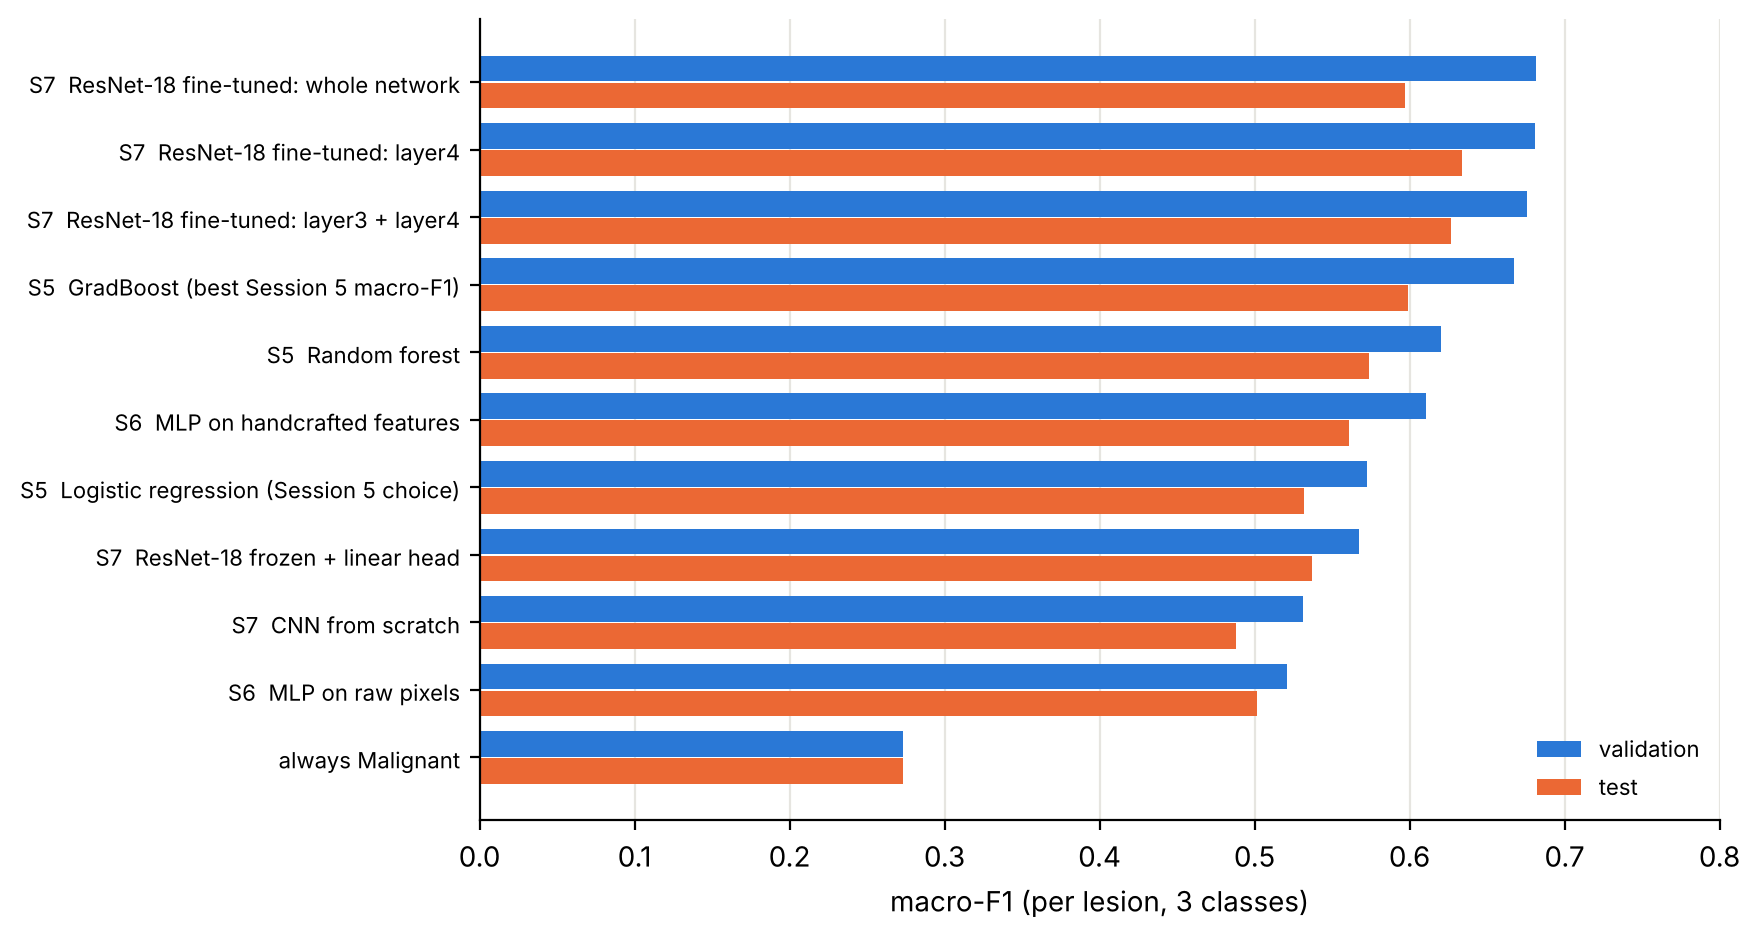

In [40]:
# PURPOSE: the scoreboard as a picture: validation and test side by side for every model.
# HOW: horizontal bars sorted by validation macro-F1; the reference row shows what the majority class scores.

shown = board.iloc[::-1]                                   # best at the top
y_pos = np.arange(len(shown))
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.barh(y_pos + 0.2, shown["val macro-F1"], height=0.38, color="#2a78d6", label="validation")
ax.barh(y_pos - 0.2, shown["test macro-F1"], height=0.38, color="#eb6834", label="test")
ax.set_yticks(y_pos, [f"S{s}  {m}" if s != "ref" else m for s, m in zip(shown["session"], shown["model"])],
              fontsize=8)
ax.set_xlabel("macro-F1 (per lesion, 3 classes)"); ax.set_xlim(0, 0.8)
ax.grid(axis="x", color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.savefig(FIG / "scoreboard.png", dpi=150, bbox_inches="tight")

#### 12.3 Our best model and its number

The best model is the one with the highest **validation** macro-F1 (the rule we used for every other choice); its test score is the number we bring to Session 8.

best model (chosen on validation): S7 ResNet-18 fine-tuned: whole network
  validation macro-F1 0.682
  test macro-F1       0.597   (95% CI 0.549 to 0.645)
  test recall per class: {'Benign': 0.695, 'Indeterminate': 0.333, 'Malignant': 0.857}
  test accuracy 0.799


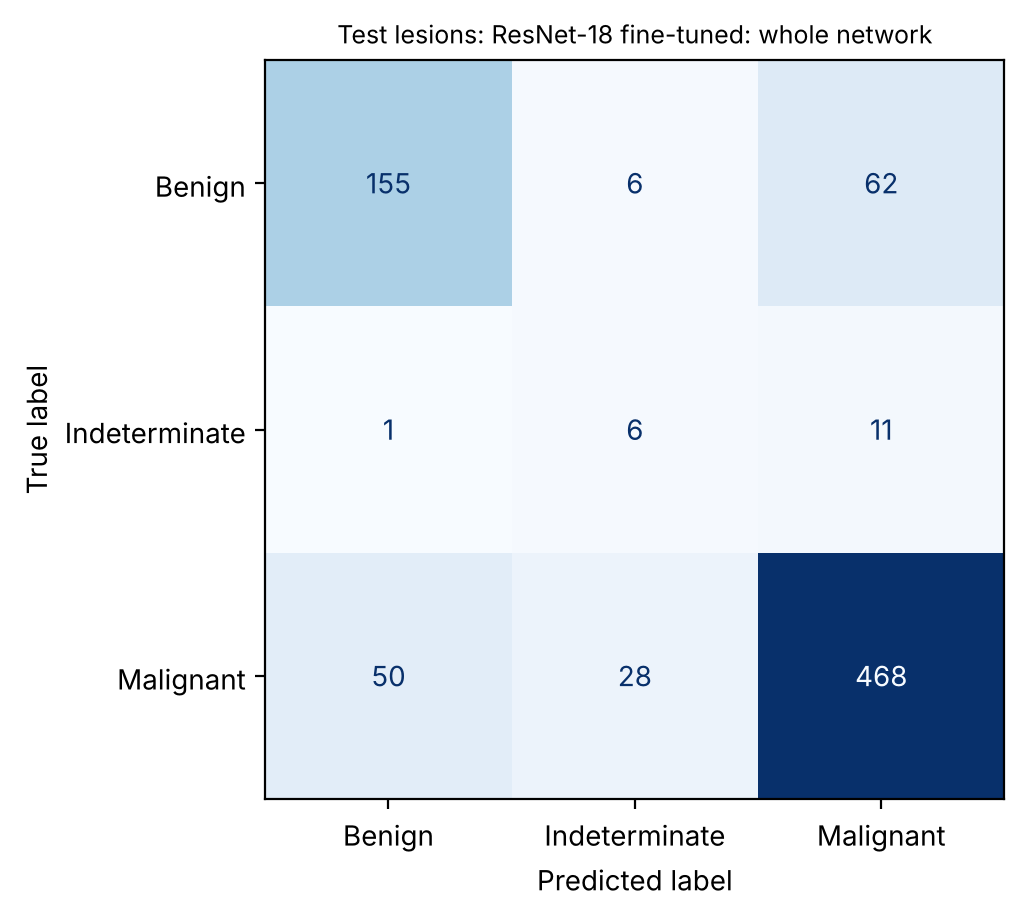

In [41]:
# PURPOSE: name the best model, give its number, and look at its test errors class by class.
# HOW: take the top row of the board (highest validation macro-F1), then its test confusion matrix and recalls.

best_row = board.iloc[0]
best_entry = next(e for e in entries if e["model"] == best_row["model"])
print(f"best model (chosen on validation): S{best_row['session']} {best_row['model']}")
print(f"  validation macro-F1 {best_row['val macro-F1']:.3f}")
print(f"  test macro-F1       {best_row['test macro-F1']:.3f}   (95% CI {best_row['test 95% CI']})")

pred = best_entry["test_pred"]
recall = {c: float((pred[y_test == k] == k).float().mean()) for k, c in enumerate(CLASSES)}
print("  test recall per class:", {c: round(r, 3) for c, r in recall.items()})
print(f"  test accuracy {accuracy_score(y_test, pred):.3f}")

disp = ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=CLASSES, cmap="Blues", colorbar=False)
disp.ax_.set_title(f"Test lesions: {best_row['model']}", fontsize=9)
disp.figure_.savefig(FIG / "best_model_test_confusion.png", dpi=150, bbox_inches="tight")

**Our best model: ResNet-18 fine-tuned as a whole (strategy 3). Validation macro-F1 0.682, test macro-F1 0.597 (95% CI 0.549 to 0.645).**

It wins on validation by less than 0.001 over `layer4` + `fc` (0.6816 against 0.6812), a tie in practice. We keep the rule fixed before opening the test set (highest validation macro-F1) instead of switching to the model with the better test score (`layer4`, 0.634): choosing on test would make the test number optimistic. What the board says:

* **Fine-tuned ResNet-18 is the best family.** The three fine-tuned ResNets are the top three on validation (0.676 to 0.682) and score 0.597 to 0.634 on test. Seeing only the dermoscopic image, they match the best classical model, which also uses the clinical image and the metadata (gradient boosting, 0.667 validation, 0.599 test), and they beat the models that see the same dermoscopic image through handcrafted features (random forest 0.621 / 0.574, MLP 0.611 / 0.561).
* **Pretraining is what makes the CNN work.** From scratch, our CNN (0.531 / 0.488) is no better than the MLP on flattened pixels (0.521 / 0.502), and both lose to the handcrafted features. The frozen ImageNet backbone alone is not enough either (0.567 / 0.537): the gain comes when `layer4` adapts to dermoscopy.
* **Session 6's question, features or pixels:** for an MLP, the 131 handcrafted features beat 3,072 raw pixels (0.611 against 0.521 on validation). The features were the MLP's ceiling; learned convolutional features from a pretrained network go past it.
* **Validation is optimistic, mostly because of 18 lesions.** Every model loses between 0.02 and 0.085 from validation to test, and the winners of their contests lose most (whole network 0.085; gradient boosting, the best of 40 classical configurations, 0.069). For the fine-tuned ResNets, Benign and Malignant F1 hold up on test (about 0.72 and 0.86); the drop is the Indeterminate class. The best model finds 6 of the 18 Indeterminate test lesions (14 of 18 on validation) and `layer4` finds 10: those 4 lesions are the whole test gap between the two models, which is why their intervals overlap so much.
* **In clinical terms**, the best model calls 468 of the 546 malignant test lesions malignant (sensitivity 0.857) and misses 50 as benign, while 62 of the 223 benign lesions are flagged as malignant.

#### 12.4 Reading: how DenseNet and EfficientNet differ from ResNet

* **DenseNet** (Huang et al., 2017): where a ResNet block *adds* its input to its output (`F(x) + x`), a DenseNet block *concatenates* the feature maps of all earlier layers and feeds them to every later layer, so features are reused instead of relearned and the network needs fewer weights (DenseNet-121: 8.0 M weights, 74.4% ImageNet top-1, against 11.7 M and 69.8% for our ResNet-18).
* **EfficientNet** (Tan and Le, 2019): instead of growing only the depth as ResNet does (18 → 34 → 50 → 152 layers), it scales depth, width and input resolution together with one compound coefficient, starting from a small network found by architecture search and built from mobile inverted-residual blocks with depthwise convolutions and squeeze-and-excitation (EfficientNet-B0: 5.3 M weights, 77.7% top-1 in torchvision).

References: G. Huang, Z. Liu, L. van der Maaten, K. Q. Weinberger, *Densely Connected Convolutional Networks*, CVPR 2017. M. Tan, Q. V. Le, *EfficientNet: Rethinking Model Scaling for Convolutional Neural Networks*, ICML 2019. Weight counts and top-1 accuracies: torchvision model documentation (`IMAGENET1K_V1` weights).